# Section 3: Shift Analysis

## 3.1 Night-shift effects

Questions:
- Are backward-fan field failures associated with night shift?
- Are fan rotation test errors associated with night shift?
- Do these associations remain when comparing units from the same
  facility and coil supplier?

Analyze field failures and test errors separately.

All proportions describe the supplied failure cases, not all units
manufactured.

In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
from IPython.display import display
from scipy.stats import binomtest, hypergeom

df = pd.read_excel("DataSets/Competition_Dataset_Final.xlsx")

# Check that each row represents a different unit.
assert df["Serial Number"].is_unique
assert set(df["Shift"]) == {"Day", "Night"}

# True means the unit has this particular outcome.
df["field_fan"] = df["Failure Description"].eq(
    "Condenser Fan Backwards"
)

df["test_fan"] = df["Failure Mode Rework"].eq(
    "Fan Rotation Error"
)

outcomes = {
    "field_fan": "Backward fan in field",
    "test_fan": "Fan rotation error at test"
}

print("Units:", len(df))
display(df["Shift"].value_counts().rename("Units"))

Units: 3000


Shift
Day      1801
Night    1199
Name: Units, dtype: int64

In [2]:
rows = []

for outcome, label in outcomes.items():
    for shift in ["Day", "Night"]:
        group = df.loc[df["Shift"].eq(shift), outcome]

        cases = len(group)
        fan_cases = int(group.sum())

        interval = binomtest(
            fan_cases, cases
        ).proportion_ci(method="wilson")

        rows.append({
            "Outcome": label,
            "Shift": shift,
            "Cases": cases,
            "Fan cases": fan_cases,
            "Percent": 100 * fan_cases / cases,
            "CI low": 100 * interval.low,
            "CI high": 100 * interval.high
        })

shift_summary = pd.DataFrame(rows)

display(shift_summary.round(2))

,Outcome,Shift,Cases,Fan cases,Percent,CI low,CI high
0,Backward fan in field,Day,1801,0,0.00,0.00,0.21
1,Backward fan in field,Night,1199,185,15.43,13.50,17.58
2,Fan rotation error at test,Day,1801,0,0.00,0.00,0.21
3,Fan rotation error at test,Night,1199,181,15.10,13.18,17.23


### Overall shift comparison

Backward-fan field failures occur in 185 of 1,199 night-shift cases
(15.43%), compared with 0 of 1,801 day-shift cases.

Fan rotation test errors occur in 181 night-shift cases (15.10%),
compared with 0 day-shift cases.

The night-shift 95% Wilson intervals are:
- Field backward-fan proportion: 13.50%–17.58%.
- Test rotation-error proportion: 13.18%–17.23%.

For each daytime outcome, the interval is approximately 0%–0.21%.
An observed zero does not establish that the underlying probability
is exactly zero.

These are unadjusted comparisons. Next, compare shifts within the
same facility and supplier.

In [3]:
within_groups = (
    df.groupby(["Facility", "Coil Supplier", "Shift"])
    .agg(
        Cases=("field_fan", "size"),
        Field_fan_cases=("field_fan", "sum"),
        Test_fan_cases=("test_fan", "sum")
    )
)

within_groups["Field fan (%)"] = (
    100 * within_groups["Field_fan_cases"]
    / within_groups["Cases"]
)

within_groups["Test fan (%)"] = (
    100 * within_groups["Test_fan_cases"]
    / within_groups["Cases"]
)

display(within_groups.round(2))

Cases  Field_fan_cases  Test_fan_cases  \
Facility   Coil Supplier Shift                                           
Facility 1 Supplier A    Day      162                0               0   
                         Night    109               31              25   
           Supplier B    Day      135                0               0   
                         Night     86               10               7   
           Supplier C    Day      140                0               0   
                         Night    116               33              18   
Facility 2 Supplier A    Day      177                0               0   
                         Night     87                2               3   
           Supplier B    Day      141                0               0   
                         Night    107               11              12   
           Supplier C    Day      169                0               0   
                         Night    103               10              12   
Facility 3 Supplier A    Day      160                0               0   
                         Night    104               22              27   
           Supplier B    Day      122                0               0   
                         Night     90                5               7   
           Supplier C    Day      163                0               0   
                         Night    113               15              18   
Facility 4 Supplier A    Day      139                0               0   
                         Night    101               23              25   
           Supplier B    Day      132                0               0   
                         Night     81                8              10   
           Supplier C    Day      161                0               0   
                         Night    102               15              17   

                                Field fan (%)  Test fan (%)  
Facility   Coil Supplier Shift                               
Facility 1 Supplier A    Day             0.00          0.00  
                         Night          28.44         22.94  
           Supplier B    Day             0.00          0.00  
                         Night          11.63          8.14  
           Supplier C    Day             0.00          0.00  
                         Night          28.45         15.52  
Facility 2 Supplier A    Day             0.00          0.00  
                         Night           2.30          3.45  
           Supplier B    Day             0.00          0.00  
                         Night          10.28         11.21  
           Supplier C    Day             0.00          0.00  
                         Night           9.71         11.65  
Facility 3 Supplier A    Day             0.00          0.00  
                         Night          21.15         25.96  
           Supplier B    Day             0.00          0.00  
                         Night           5.56          7.78  
           Supplier C    Day             0.00          0.00  
                         Night          13.27         15.93  
Facility 4 Supplier A    Day             0.00          0.00  
                         Night          22.77         24.75  
           Supplier B    Day             0.00          0.00  
                         Night           9.88         12.35  
           Supplier C    Day             0.00          0.00  
                         Night          14.71         16.67

In [4]:
def stratified_shift_test(data, outcome):
    # Distribution of total night events under no shift association.
    null_distribution = np.array([1.0])

    for _, group in data.groupby(["Facility", "Coil Supplier"]):
        total = len(group)
        night = int(group["Shift"].eq("Night").sum())
        events = int(group[outcome].sum())

        possible_counts = np.arange(events + 1)

        probabilities = hypergeom.pmf(
            possible_counts, total, events, night
        )

        null_distribution = np.convolve(
            null_distribution, probabilities
        )

    observed = int(
        data.loc[data["Shift"].eq("Night"), outcome].sum()
    )

    lower_tail = null_distribution[:observed + 1].sum()
    upper_tail = null_distribution[observed:].sum()

    # Two-sided test: twice the smaller tail, capped at 1.
    return min(1.0, 2 * min(lower_tail, upper_tail))


for outcome, label in outcomes.items():
    p_value = stratified_shift_test(df, outcome)
    print(f"{label}: adjusted p-value = {p_value:.3e}")

Backward fan in field: adjusted p-value = 4.734e-77
Fan rotation error at test: adjusted p-value = 9.432e-76


### Comparison controlling for facility and supplier

Both fan outcomes remain associated with night shift after conditioning
on facility and coil supplier.

Every facility/supplier combination contains both day- and night-shift
units. In each combination, fan events occur only among night-shift units.

Two-sided exact stratified tests give:
- Field backward-fan outcome: p < 0.001.
- Test rotation-error outcome: p < 0.001.

The tests condition on group sizes and event totals and assume independent
units. Differences in the recorded facility/supplier mix alone do not
explain the observed pattern.

This supports investigating night-shift assembly and verification
practices. It does not establish that shift itself causes the errors,
and other influences may remain uncontrolled.

## 3.2 Cost attached

Summarize recorded expenses and labor for:
- All night-shift units.
- Units with backward-fan field failures.
- Units with fan rotation test errors.
- Units with factory fan rotation corrections.

These groups overlap and must not be added together.

Keep warranty expense and field-service repair expense separate because
their accounting overlap is unclear. Report labor hours separately
until an hourly labor cost is justified.

In [5]:
groups = {
    "All night-shift units": df["Shift"].eq("Night"),

    "Field backward-fan units": df["field_fan"],

    "Test rotation-error units": df["test_fan"],

    "Factory fan-correction units": df["Repair Type"].eq(
        "Fan Rotation Correction"
    )
}

rows = []

for label, mask in groups.items():
    group = df.loc[mask]

    rows.append({
        "Group": label,
        "Units": len(group),
        "Warranty ($)": group["Warranty Cost"].sum(),
        "Field repair ($)": group["Repair Cost Field Service"].sum(),
        "Plant material ($)": group["Material Cost Rework"].sum(),
        "Plant labor (h)": group["Labor Hours Rework"].sum(),
        "EOLT rework (h)": group["EOLT Rework Hours"].sum()
    })

cost_summary = pd.DataFrame(rows).set_index("Group")

display(cost_summary.round(2))

,Units,Warranty ($),Field repair ($),Plant material ($),Plant labor (h),EOLT rework (h)
Group,,,,,,
All night-shift units,1199,3055174,1527286,319400,3906.0,2484.2
Field backward-fan units,185,136427,68171,49899,615.1,371.2
Test rotation-error units,181,141679,70796,49437,585.2,361.1
Factory fan-correction units,366,278302,139059,96953,1198.4,753.5


### Recorded cost findings

The 185 backward-fan field cases have:
- $136,427 in recorded warranty expense.
- $68,171 in recorded field-service repair expense.

The 366 factory fan-correction records have:
- $96,953 in recorded plant material costs.
- 1,198.4 hours of plant rework labor.
- 753.5 hours of EOLT rework.

All factory fan-correction records involve night-shift units.

At an agreed plant labor rate of R dollars per hour, recorded factory
material plus rework labor cost would be:

$96,953 + (1,198.4 × R)

EOLT hours remain separate until their relationship to plant labor hours
and their applicable hourly rate are confirmed.

These amounts describe recorded costs on the selected units. They are
not estimates of costs caused by night shift or guaranteed savings from
an intervention. Costs across overlapping groups must not be summed.

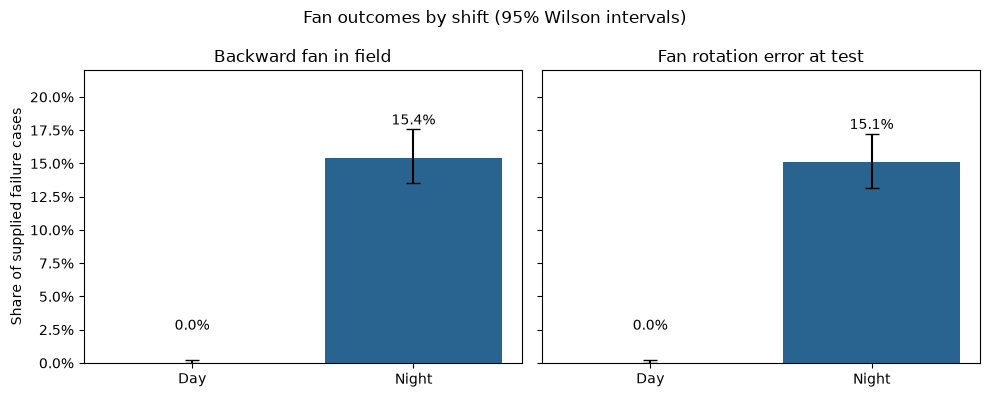

In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter

figures = Path("Figures") / "Section3"
figures.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(
    1, 2, figsize=(10, 4), sharey=True
)

for ax, label in zip(axes, outcomes.values()):
    values = (
        shift_summary.loc[shift_summary["Outcome"].eq(label)]
        .set_index("Shift")
        .loc[["Day", "Night"]]
    )

    errors = np.vstack([
        np.maximum(0, values["Percent"] - values["CI low"]),
        np.maximum(0, values["CI high"] - values["Percent"])
    ])

    ax.bar(
        values.index,
        values["Percent"],
        yerr=errors,
        capsize=5,
        color=["#A6ADB4", "#28648F"]
    )

    ax.set_title(label)
    ax.set_ylim(0, 22)
    ax.yaxis.set_major_formatter(PercentFormatter(100))

    for x, row in enumerate(values.itertuples()):
        ax.text(
            x, row.Percent + 2.5,
            f"{row.Percent:.1f}%",
            ha="center"
        )

axes[0].set_ylabel("Share of supplied failure cases")
fig.suptitle("Fan outcomes by shift (95% Wilson intervals)")

plt.tight_layout()
plt.savefig(
    figures / "fan_outcomes_by_shift.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

### Figure interpretation

Both fan outcomes appear only among night-shift units in the supplied
failure cases. Error bars show 95% Wilson confidence intervals.

The chart displays unadjusted proportions. The separate stratified tests
show that the shift association persists when controlling for facility
and supplier.

## Conclusion and cause verification

Both backward-fan field failures and fan rotation test errors are
associated with the recorded Night shift. This association remains
after controlling for facility and coil supplier.

This does not establish that fans were installed incorrectly during
night shift. The Shift label comes from rework and EOLT records;
the dataset does not separately identify the fan installation shift.

Both shifts have EOLT records, but the data does not confirm whether
every unit received the same fan-direction check. Differences in
installation, inspection, work assignments, or reporting remain
possible explanations.

### Recommended verification

1. Confirm whether Shift identifies assembly, rework, or testing.
2. Check whether both shifts install fans and perform the same
   fan-direction inspection.
3. Inspect comparable units from both shifts using the same procedure,
   including units without field failures.
4. Record fan direction before and after rework to distinguish
   installation errors from problems introduced or missed during repair.

The current evidence supports investigating the night-associated
fan process. It does not yet identify a confirmed cause or establish
how much an intervention would save.